# Mass–Richness Relation vs Magnitude Gap  (colossus c–M prior)

Variant of `wazp_mass_richness_by_delta_m.ipynb`. Same per-cell-median split into low-Δm / high-Δm sub-stacks, same boost-corrected `stacked_signal`, same `xlensing.model.NFW_Delta_Sigma` likelihood — but **concentration is no longer a free parameter**. Each likelihood call evaluates a deterministic concentration-from-mass relation from `colossus.halo.concentration` at the current $M$ and the stack's mean redshift.

**Mass-definition convention.** `xlensing.model.NFW_Delta_Sigma` uses the **$M_{200c}$** definition (mass enclosed within $R_{200c}$, where $\bar\rho = 200\rho_{\rm crit}$), even though the parameter names are spelled `M200m` / `C200m`. We therefore query `colossus.halo.concentration.concentration(..., mdef='200c', ...)` for $c_{200c}$.

**Free parameters per stack** (3, down from 4):

- `log10(M200c)` ∈ [13, 16]
- `FMISS` ∈ [0, 1]
- `SIGMA_OFF` ∈ [0.01, 1.0]  Mpc

**c–M relation:** configurable via `CMR_MODEL` in the imports cell. Default is `'diemer19'` (Diemer & Joyce 2019). Other options: `'duffy08'`, `'dutton14'`, `'bhattacharya13'`, `'klypin16'`.

**Unit note.** Colossus expects mass in $M_\odot/h$; xlensing expects $M_\odot$. The likelihood converts when querying colossus and passes plain $M_\odot$ to the NFW model.

Pre-filter: drop clusters with `DELTA_M_I ≤ 0` or non-finite `DELTA_M_I`.

Pipeline:

1. Load WaZP real-data catalog + metacal source pre-filter + BallTree (§1).
2. Bin definitions: 3 z × 4 NGALS × 2 per-cell-median Δm halves (§2).
3. Reuse `data/wazp_bkgs.pkl` (or compute) the per-cluster `bkg` arrays (§3).
4. Stack the cells via `xlensing.data.stacked_signal` with boost correction (§4).
5. Plot the stacks, low-Δm row / high-Δm row × z columns (§5).
6. Fit each stack with `xlensing.model.NFW_Delta_Sigma`; $c$ from colossus (§6).
7. Per Δm group, fit the joint M–λ–$z$ power law (§7).
8. Contour plot comparing the two Δm groups in $(\log M_0, \alpha, \beta)$ (§8).

Outputs go to `data/wazp_mr_dm_colossus_*.pkl` so they don't collide with the parent notebook's results. The bkg cache (`data/wazp_bkgs.pkl`) is shared.

In [1]:
import os, time, pickle, warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from astropy.table import Table
from astropy.cosmology import Planck18 as COSMO
from astropy import units as u
from sklearn.neighbors import BallTree
from multiprocess import Pool, cpu_count
from nautilus import Prior, Sampler
import corner
import xlensing.data
import xlensing.model

# Colossus c-M relation
from colossus.cosmology import cosmology as colossus_cosmo
from colossus.halo      import concentration as colossus_conc
colossus_cosmo.setCosmology('planck18')
COLOSSUS_H = colossus_cosmo.getCurrent().h     # for Msun -> Msun/h conversion

warnings.filterwarnings('ignore')

WAZP_REAL    = 'data/wazp_real_data.fits'
FILTERED_NPZ = 'data/metacal_filtered.npz'
BKG_CACHE    = 'data/wazp_bkgs.pkl'                              # shared with parent notebook
STACKS_PKL   = 'data/wazp_mr_dm_colossus_stacks.pkl'
FITS_PKL     = 'data/wazp_mr_dm_colossus_fits.pkl'
ML_PKL       = 'data/wazp_mr_dm_colossus_ml.pkl'

USE_CACHE  = False        # set to False to force a clean rebuild of every intermediate
RADIUS_MPC = 5.0
NBOOT      = 500
NLIVE      = 400
NWORKERS   = max(1, cpu_count() - 1)

# colossus c-M settings
CMR_MODEL  = 'diemer19'   # 'duffy08', 'dutton14', 'bhattacharya13', 'klypin16', ...
CMR_MDEF   = '200c'       # xlensing uses 200c convention

radii  = np.logspace(-0.6, 0.6, 12)
_N     = len(radii)
_edges = np.logspace(
    np.log10(radii[0])   + (np.log10(radii[0]) - np.log10(radii[1])) / 2,
    np.log10(radii[-1])  - (np.log10(radii[0]) - np.log10(radii[1])) / 2,
    _N + 1,
)
BINS_LIMS = np.array([[_edges[i], _edges[i+1]] for i in range(_N)])

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
os.makedirs('data', exist_ok=True)

# Quick sanity check of the c-M relation
_c_test = colossus_conc.concentration(
    M=1e14 * COLOSSUS_H, mdef=CMR_MDEF, z=0.4, model=CMR_MODEL,
)
print(f'USE_CACHE = {USE_CACHE}')
print(f'CMR_MODEL = {CMR_MODEL}   ({CMR_MDEF}, colossus h={COLOSSUS_H:.4f})')
print(f'    sanity: c({CMR_MDEF})(M=1e14 Msun, z=0.4) = {_c_test:.3f}')
print(f'NWORKERS  = {NWORKERS}')
print(f'NBOOT     = {NBOOT}')
print(f'NLIVE     = {NLIVE}')

Lookup tables loaded!
USE_CACHE = False
CMR_MODEL = diemer19   (200c, colossus h=0.6766)
    sanity: c(200c)(M=1e14 Msun, z=0.4) = 4.104
NWORKERS  = 15
NBOOT     = 500
NLIVE     = 400


## 1 — Catalogs and BallTree

In [2]:
wazp_all = Table.read(WAZP_REAL)
print(f'Loaded {len(wazp_all):,} clusters from {WAZP_REAL}')

# Drop non-finite and non-positive Δm (cluster-finder artefacts)
keep = np.isfinite(wazp_all['DELTA_M_I']) & (wazp_all['DELTA_M_I'] > 0)
wazp = wazp_all[keep]
print(f'After Δm > 0 cut: {len(wazp):,}  '
      f'(dropped {len(wazp_all)-len(wazp):,})')

if not os.path.exists(FILTERED_NPZ):
    raise FileNotFoundError(
        f'{FILTERED_NPZ} not found. Run wazp_lensing_signals.ipynb §2 first.'
    )
f = np.load(FILTERED_NPZ)
SR_RA  = f['ra'];  SR_DEC = f['dec']; SR_Z = f['z']
SR_E1  = f['e1'];  SR_E2  = f['e2'];  SR_W = f['w']
SR_R11 = f['R11']; SR_R12 = f['R12']
SR_R21 = f['R21']; SR_R22 = f['R22']
print(f'Loaded {len(SR_RA):,} pre-filtered sources')

t0 = time.time()
TREE = BallTree(np.column_stack([SR_DEC, SR_RA]), metric='haversine')
print(f'BallTree built in {time.time()-t0:.1f}s')

Loaded 15,967 clusters from data/wazp_real_data.fits
After Δm > 0 cut: 15,825  (dropped 142)
Loaded 126,719,902 pre-filtered sources
BallTree built in 80.0s


## 2 — Bin definitions  (3 z × 3 NGALS × 2 Δm)

- **z** (fixed): `[0.10, 0.35, 0.55, 0.70]`
- **NGALS** (fixed, 4 bins log-spaced 25→168.8 with a tail to ∞):
  `[25, 47.3, 89.4, 168.8, ∞]` — geometric spacing with ratio ≈ 1.89 between consecutive edges. The top finite edge is set at $\lambda=168.8$ rather than $\lambda=200$ so the to-∞ bin captures the otherwise-thin $\lambda\in[169,200]$ population.
- **Δm** (per-cell median): within each (z, NGALS) cell, split the (Δm > 0) clusters at the cell median; `dm=0` is below, `dm=1` is above.

In [3]:
z_edges  = np.array([0.10, 0.30, 0.50, 0.60])
# Log-spaced richness edges 25 -> 168.8 (top finite edge below 200 so the
# to-infinity bin catches λ ∈ [169, 200] clusters where the population
# is otherwise thin), plus a tail to ∞.  Ratio ≈ 1.89 between edges.
ng_edges = np.array([25., 50., 75., 150.,np.inf])
N_NG     = len(ng_edges) - 1   # 4 NGALS bins

def bin_idx(values, edges):
    v   = np.asarray(values, dtype=float)
    idx = np.digitize(v, edges[1:-1], right=False)
    out = ~((v >= edges[0]) & (v <= edges[-1]))
    idx[out] = -1
    return idx

z_bin  = bin_idx(wazp['ZPHOT'], z_edges)
ng_bin = bin_idx(wazp['NGALS'], ng_edges)
dm_bin = np.full(len(wazp), -1, dtype=int)
dm_median_per_cell = {}

for i in range(3):
    for j in range(N_NG):
        cell = (z_bin == i) & (ng_bin == j)
        if cell.sum() < 2:
            dm_median_per_cell[(i, j)] = None
            continue
        cell_dm = np.asarray(wazp['DELTA_M_I'])[cell]
        med = float(np.median(cell_dm))
        dm_median_per_cell[(i, j)] = med
        glob_idx = np.where(cell)[0]
        dm_bin[glob_idx[cell_dm <  med]] = 0
        dm_bin[glob_idx[cell_dm >= med]] = 1

# Diagnostic table
print(f'{"cell":>6}  {"z":>14}  {"NGALS":>15}  '
      f'{"N_low":>7}  {"N_high":>7}  {"med Δm":>7}')
print('-' * 72)
for i in range(3):
    for j in range(N_NG):
        nlow  = int(((z_bin==i) & (ng_bin==j) & (dm_bin==0)).sum())
        nhigh = int(((z_bin==i) & (ng_bin==j) & (dm_bin==1)).sum())
        med   = dm_median_per_cell[(i, j)]
        med_s = f'{med:.2f}' if med is not None else '—'
        hi = (f'{ng_edges[j+1]:.1f}'
              if np.isfinite(ng_edges[j+1]) else 'inf')
        print(f'{"("+str(i)+","+str(j)+")":>6}  '
              f'[{z_edges[i]:.2f},{z_edges[i+1]:.2f}){" ":>3}  '
              f'[{ng_edges[j]:.1f},{hi}){" ":>3}  '
              f'{nlow:>7,}  {nhigh:>7,}  {med_s:>7}')

  cell               z            NGALS    N_low   N_high   med Δm
------------------------------------------------------------------------
 (0,0)  [0.10,0.30)     [25.0,50.0)         671      672     0.69
 (0,1)  [0.10,0.30)     [50.0,75.0)         134      134     0.76
 (0,2)  [0.10,0.30)     [75.0,150.0)          65       65     0.70
 (0,3)  [0.10,0.30)     [150.0,inf)           9       10     0.77
 (1,0)  [0.30,0.50)     [25.0,50.0)       2,584    2,585     0.67
 (1,1)  [0.30,0.50)     [50.0,75.0)         539      540     0.75
 (1,2)  [0.30,0.50)     [75.0,150.0)         235      236     0.70
 (1,3)  [0.30,0.50)     [150.0,inf)          29       30     0.72
 (2,0)  [0.50,0.60)     [25.0,50.0)       1,434    1,435     0.58
 (2,1)  [0.50,0.60)     [50.0,75.0)         232      233     0.58
 (2,2)  [0.50,0.60)     [75.0,150.0)          87       87     0.59
 (2,3)  [0.50,0.60)     [150.0,inf)           4        5     0.42


## 3 — Per-cluster `bkg` arrays

Reuse `data/wazp_bkgs.pkl` if present; otherwise compute in parallel.

In [4]:
def bkg_worker(row):
    try:
        cid   = int(row['ID'])
        z_cl  = float(row['ZPHOT'])
        ra_r  = np.deg2rad(float(row['RA']))
        dec_r = np.deg2rad(float(row['DEC']))

        D_A = float(COSMO.angular_diameter_distance(z_cl).to_value(u.Mpc))
        if D_A <= 0:
            return {'ID': cid, 'error': f'D_A={D_A}'}
        ang_r = RADIUS_MPC / D_A

        idx = TREE.query_radius(np.array([[dec_r, ra_r]]), r=ang_r)[0]
        if len(idx) == 0:
            return {'ID': cid, 'bkg': None, 'count': 0}

        sources = (
            SR_RA [idx], SR_DEC[idx], SR_Z [idx],
            SR_E1 [idx], SR_E2 [idx], SR_W [idx],
            SR_R11[idx], SR_R12[idx], SR_R21[idx], SR_R22[idx],
        )
        res = xlensing.data.metacal_cluster_lensing(
            (ra_r, dec_r, z_cl), sources, radius=RADIUS_MPC,
        )
        if res['Count'] == 0:
            return {'ID': cid, 'bkg': None, 'count': 0}
        bkg = np.array([
            np.asarray(res['Critical Density'], dtype='float32'),
            np.asarray(res['Tangential Shear'], dtype='float32'),
            np.asarray(res['Cross Shear'],      dtype='float32'),
            np.asarray(res['Weights'],          dtype='float32'),
            np.asarray(res['Radial Distance'],  dtype='float32'),
            np.asarray(res['Mult. Bias'],       dtype='float32'),
        ])
        return {'ID': cid, 'bkg': bkg, 'count': int(res['Count'])}
    except Exception as exc:
        return {'ID': int(row.get('ID', -1)), 'error': repr(exc)}

In [5]:
if os.path.exists(BKG_CACHE) and USE_CACHE:
    with open(BKG_CACHE, 'rb') as fh:
        bkg_results = pickle.load(fh)
    print(f'Loaded {len(bkg_results):,} cached bkgs from {BKG_CACHE}')
else:
    if os.path.exists(BKG_CACHE):
        print(f'USE_CACHE = False, rebuilding {BKG_CACHE} from scratch')
    input_list = [
        {'ID': int(wazp_all['ID'][i]),    'RA':   float(wazp_all['RA'][i]),
         'DEC':float(wazp_all['DEC'][i]), 'ZPHOT':float(wazp_all['ZPHOT'][i])}
        for i in range(len(wazp_all))
    ]
    print(f'Computing bkgs for {len(input_list):,} clusters with {NWORKERS} workers')
    bkg_results = []
    t0 = time.time()
    with Pool(NWORKERS) as pool:
        for i, r in enumerate(pool.imap_unordered(
                bkg_worker, input_list, chunksize=4)):
            bkg_results.append(r)
            if (i + 1) % 200 == 0 or (i + 1) == len(input_list):
                dt  = time.time() - t0
                eta = dt * (len(input_list) - i - 1) / (i + 1)
                print(f'  {i+1:>6,}/{len(input_list):,}  '
                      f'elapsed {dt/60:5.1f} min  eta {eta/60:5.1f} min',
                      flush=True)
    with open(BKG_CACHE, 'wb') as fh:
        pickle.dump(bkg_results, fh)

bkg_by_id = {r['ID']: r['bkg'] for r in bkg_results
             if r.get('bkg') is not None}
print(f'Usable bkgs: {len(bkg_by_id):,}')

USE_CACHE = False, rebuilding data/wazp_bkgs.pkl from scratch
Computing bkgs for 15,967 clusters with 15 workers
     200/15,967  elapsed   0.0 min  eta   1.2 min
     400/15,967  elapsed   0.0 min  eta   0.8 min
     600/15,967  elapsed   0.0 min  eta   0.7 min
     800/15,967  elapsed   0.0 min  eta   0.7 min
   1,000/15,967  elapsed   0.0 min  eta   0.6 min
   1,200/15,967  elapsed   0.0 min  eta   0.6 min
   1,400/15,967  elapsed   0.1 min  eta   0.6 min
   1,600/15,967  elapsed   0.1 min  eta   0.6 min
   1,800/15,967  elapsed   0.1 min  eta   0.5 min
   2,000/15,967  elapsed   0.1 min  eta   0.5 min
   2,200/15,967  elapsed   0.1 min  eta   0.5 min
   2,400/15,967  elapsed   0.1 min  eta   0.5 min
   2,600/15,967  elapsed   0.1 min  eta   0.5 min
   2,800/15,967  elapsed   0.1 min  eta   0.4 min
   3,000/15,967  elapsed   0.1 min  eta   0.4 min
   3,200/15,967  elapsed   0.1 min  eta   0.4 min
   3,400/15,967  elapsed   0.1 min  eta   0.4 min
   3,600/15,967  elapsed   0.1 min  e

## 4 — Stack the 24 cells

In [6]:
def collect_bkgs(mask):
    ids = np.asarray(wazp['ID'])[mask]
    return [bkg_by_id[int(i)] for i in ids if int(i) in bkg_by_id]

# stacked_signal now returns boost-corrected ΔΣ + full propagated covariance
# (joint cluster bootstrap of boost and signal).
stacks = {}
boost_outer = []
for i in range(3):
    for j in range(N_NG):
        for k in range(2):
            name = f'z{i}_ng{j}_dm{k}'
            mask = (z_bin == i) & (ng_bin == j) & (dm_bin == k)
            if not mask.any():
                continue
            bkgs = collect_bkgs(mask)
            if not bkgs:
                continue
            t0 = time.time()
            sigmas, boosts, boosts_cov, sigmas_cov, xigmas, xigmas_cov = (
                xlensing.data.stacked_signal(bkgs, BINS_LIMS, NBOOT)
            )

            cell_z   = np.asarray(wazp['ZPHOT'])[mask]
            cell_lam = np.asarray(wazp['NGALS'])[mask]
            cell_dm  = np.asarray(wazp['DELTA_M_I'])[mask]
            stacks[name] = {
                'z_bin':     i, 'ng_bin': j, 'dm_bin': k,
                'z_lo':      float(z_edges[i]),  'z_hi':  float(z_edges[i+1]),
                'ng_lo':     float(ng_edges[j]), 'ng_hi': float(ng_edges[j+1]),
                'dm_median': dm_median_per_cell[(i, j)],
                'z_mean':       float(cell_z.mean()),
                'lambda_mean':  float(cell_lam.mean()),
                'dm_mean':      float(cell_dm.mean()),
                'n_stacked':    len(bkgs),
                'sigmas':     np.asarray(sigmas),
                'sigmas_cov': np.asarray(sigmas_cov),
                'boosts':     np.asarray(boosts),
                'boosts_cov': np.asarray(boosts_cov),
                'xigmas':     np.asarray(xigmas),
                'xigmas_cov': np.asarray(xigmas_cov),
            }
            b_err_outer = float(np.sqrt(boosts_cov[-1, -1]))
            boost_outer.append((name, float(boosts[-1]), b_err_outer))
            print(f'{name}: ⟨z⟩={cell_z.mean():.3f}  ⟨λ⟩={cell_lam.mean():6.1f}  '
                  f'⟨Δm⟩={cell_dm.mean():.2f}  N={len(bkgs):,}  '
                  f'B_outer={boosts[-1]:.3f}±{b_err_outer:.3f}  '
                  f'({time.time()-t0:.1f}s)')

b_outer = np.array([v for _, v, _ in boost_outer])
print(f'\nOuter-bin boost factor over {len(boost_outer)} stacks:')
print(f'  median = {np.median(b_outer):.3f}  mean = {b_outer.mean():.3f}  '
      f'min = {b_outer.min():.3f}  max = {b_outer.max():.3f}')
if not (0.85 < np.median(b_outer) < 1.15):
    print('  WARNING: outer-bin boost median far from 1 — check binning / random count')

with open(STACKS_PKL, 'wb') as fh:
    pickle.dump({'radii': radii, 'bins_lims': BINS_LIMS,
                 'z_edges': z_edges, 'ng_edges': ng_edges,
                 'dm_median_per_cell': dm_median_per_cell,
                 'stacks': stacks}, fh)
n_expected = 3 * N_NG * 2
print(f'\nProduced {len(stacks)}/{n_expected} stacks, saved to {STACKS_PKL}')

Total galaxies available per bin:
[   8986   13871   22250   35301   57657   92936  151398  246784  405795
  668768 1100215 1815695]

z0_ng0_dm0: ⟨z⟩=0.241  ⟨λ⟩=  33.3  ⟨Δm⟩=0.34  N=670  B_outer=0.992±0.023  (0.9s)
Total galaxies available per bin:
[   9924   15329   24939   39920   64133  103096  167136  271394  447977
  732384 1210075 1992778]

z0_ng0_dm1: ⟨z⟩=0.233  ⟨λ⟩=  33.7  ⟨Δm⟩=1.18  N=672  B_outer=0.993±0.025  (0.9s)
Total galaxies available per bin:
[  1851   2901   4405   7048  11003  18215  29539  48128  77796 129654
 215847 350355]

z0_ng1_dm0: ⟨z⟩=0.242  ⟨λ⟩=  60.1  ⟨Δm⟩=0.41  N=134  B_outer=0.985±0.056  (0.2s)
Total galaxies available per bin:
[  2045   3026   4592   7572  11907  19106  30966  50552  81475 133619
 219055 361756]

z0_ng1_dm1: ⟨z⟩=0.241  ⟨λ⟩=  60.2  ⟨Δm⟩=1.19  N=134  B_outer=0.988±0.055  (0.2s)
Total galaxies available per bin:
[   871   1322   1968   3182   5128   8350  13368  21467  35496  59307
  99844 165763]

z0_ng2_dm0: ⟨z⟩=0.248  ⟨λ⟩=  96.3  ⟨Δm⟩=0.

### 4.1 — Boost-factor diagnostic

$B(R)$ for all stacks. Boost has been applied to `sigmas` and `sigmas_cov` above. The 2×3 grid mirrors §5: rows = low/high Δm, columns = z slices, six richness curves per panel. Outer-bin boost should be near 1.

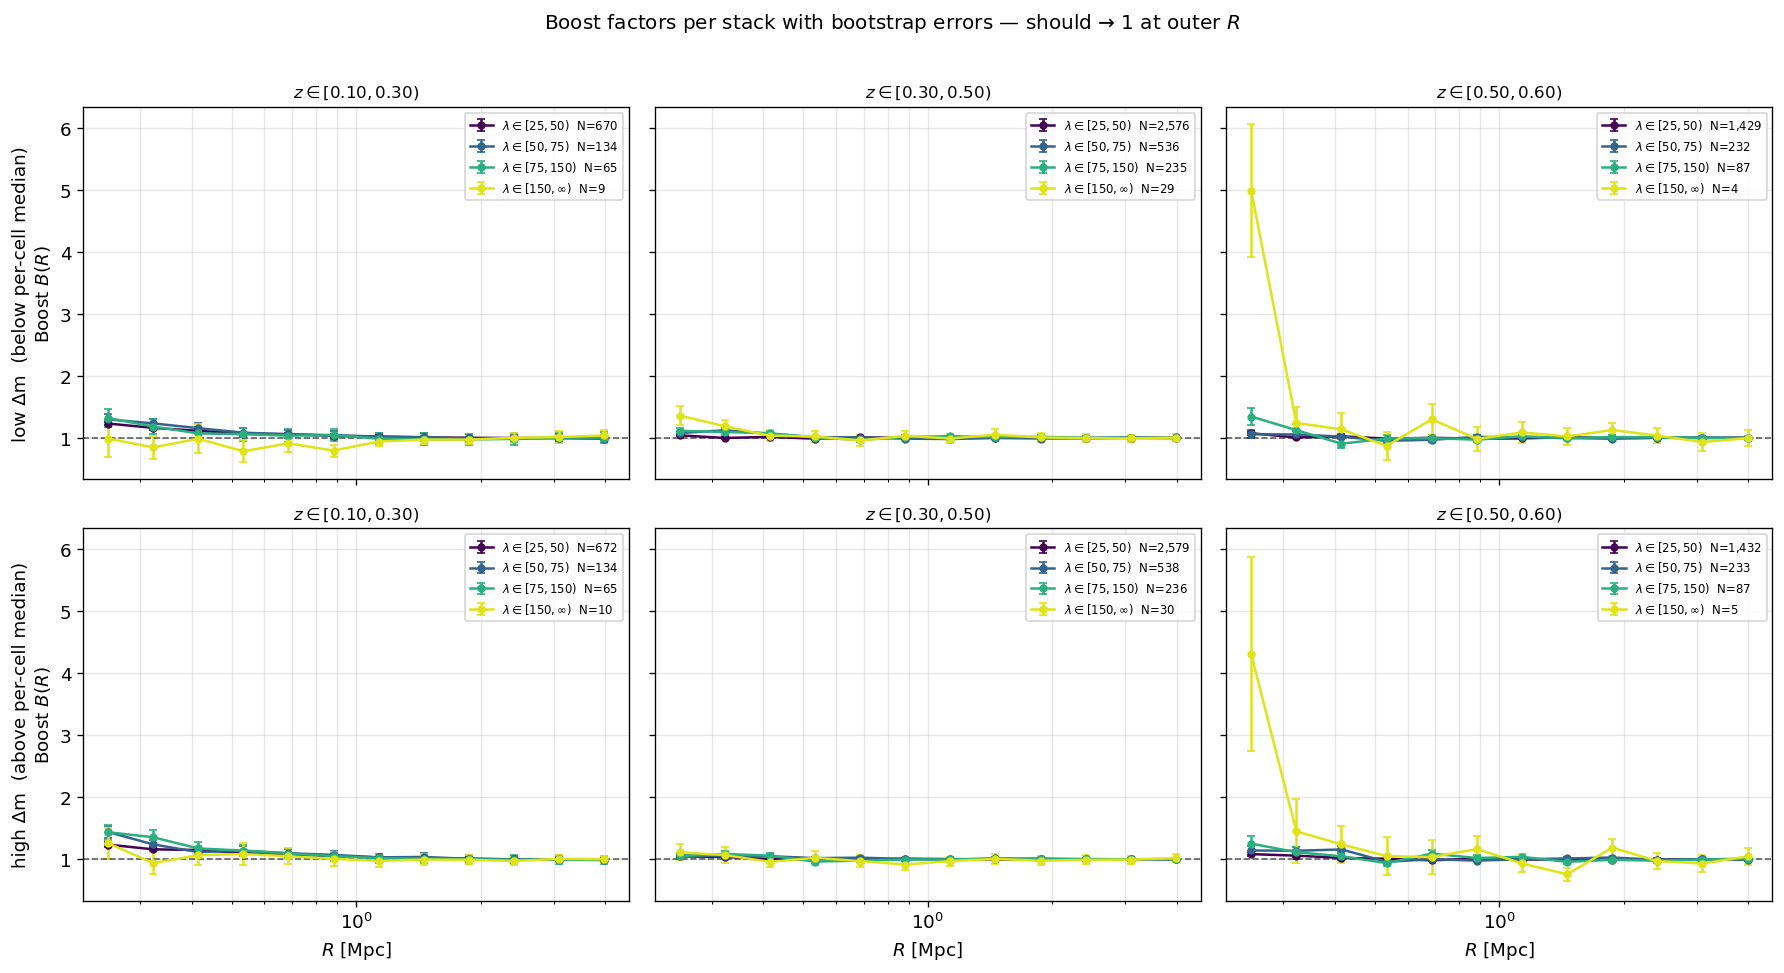

In [7]:
cmap = mpl.cm.viridis
ng_colors = [cmap(x) for x in np.linspace(0.0, 0.95, N_NG)]
dm_titles = {0: 'low Δm  (below per-cell median)',
             1: 'high Δm  (above per-cell median)'}

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for k in range(2):
    for i in range(3):
        ax = axes[k, i]
        for j in range(N_NG):
            name = f'z{i}_ng{j}_dm{k}'
            if name not in stacks: continue
            s   = stacks[name]
            hi  = (f'{s["ng_hi"]:.0f}'
                   if np.isfinite(s["ng_hi"]) else r'\infty')
            b_err = np.sqrt(np.diag(s['boosts_cov']))
            ax.errorbar(radii, s['boosts'], yerr=b_err,
                        fmt='o-', ms=4, capsize=2.5, color=ng_colors[j],
                        label=(rf'$\lambda\in[{s["ng_lo"]:.0f},{hi})$  '
                               f'N={s["n_stacked"]:,}'))
        ax.axhline(1.0, color='k', lw=1.0, ls='--', alpha=0.6)
        ax.set_xscale('log')
        if k == 1:
            ax.set_xlabel(r'$R$ [Mpc]')
        if i == 0:
            ax.set_ylabel(rf'{dm_titles[k]}'+'\n'+r'Boost $B(R)$')
        ax.set_title(rf'$z\in[{z_edges[i]:.2f},{z_edges[i+1]:.2f})$', fontsize=10)
        ax.grid(alpha=0.3, which='both')
        ax.legend(fontsize=7, loc='upper right')

plt.suptitle('Boost factors per stack with bootstrap errors — should → 1 at outer $R$',
             fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## 5 — Stacked profiles

Two rows (low-Δm vs high-Δm) × three columns (one per z slice). Within each panel the six NGALS curves are overlaid.

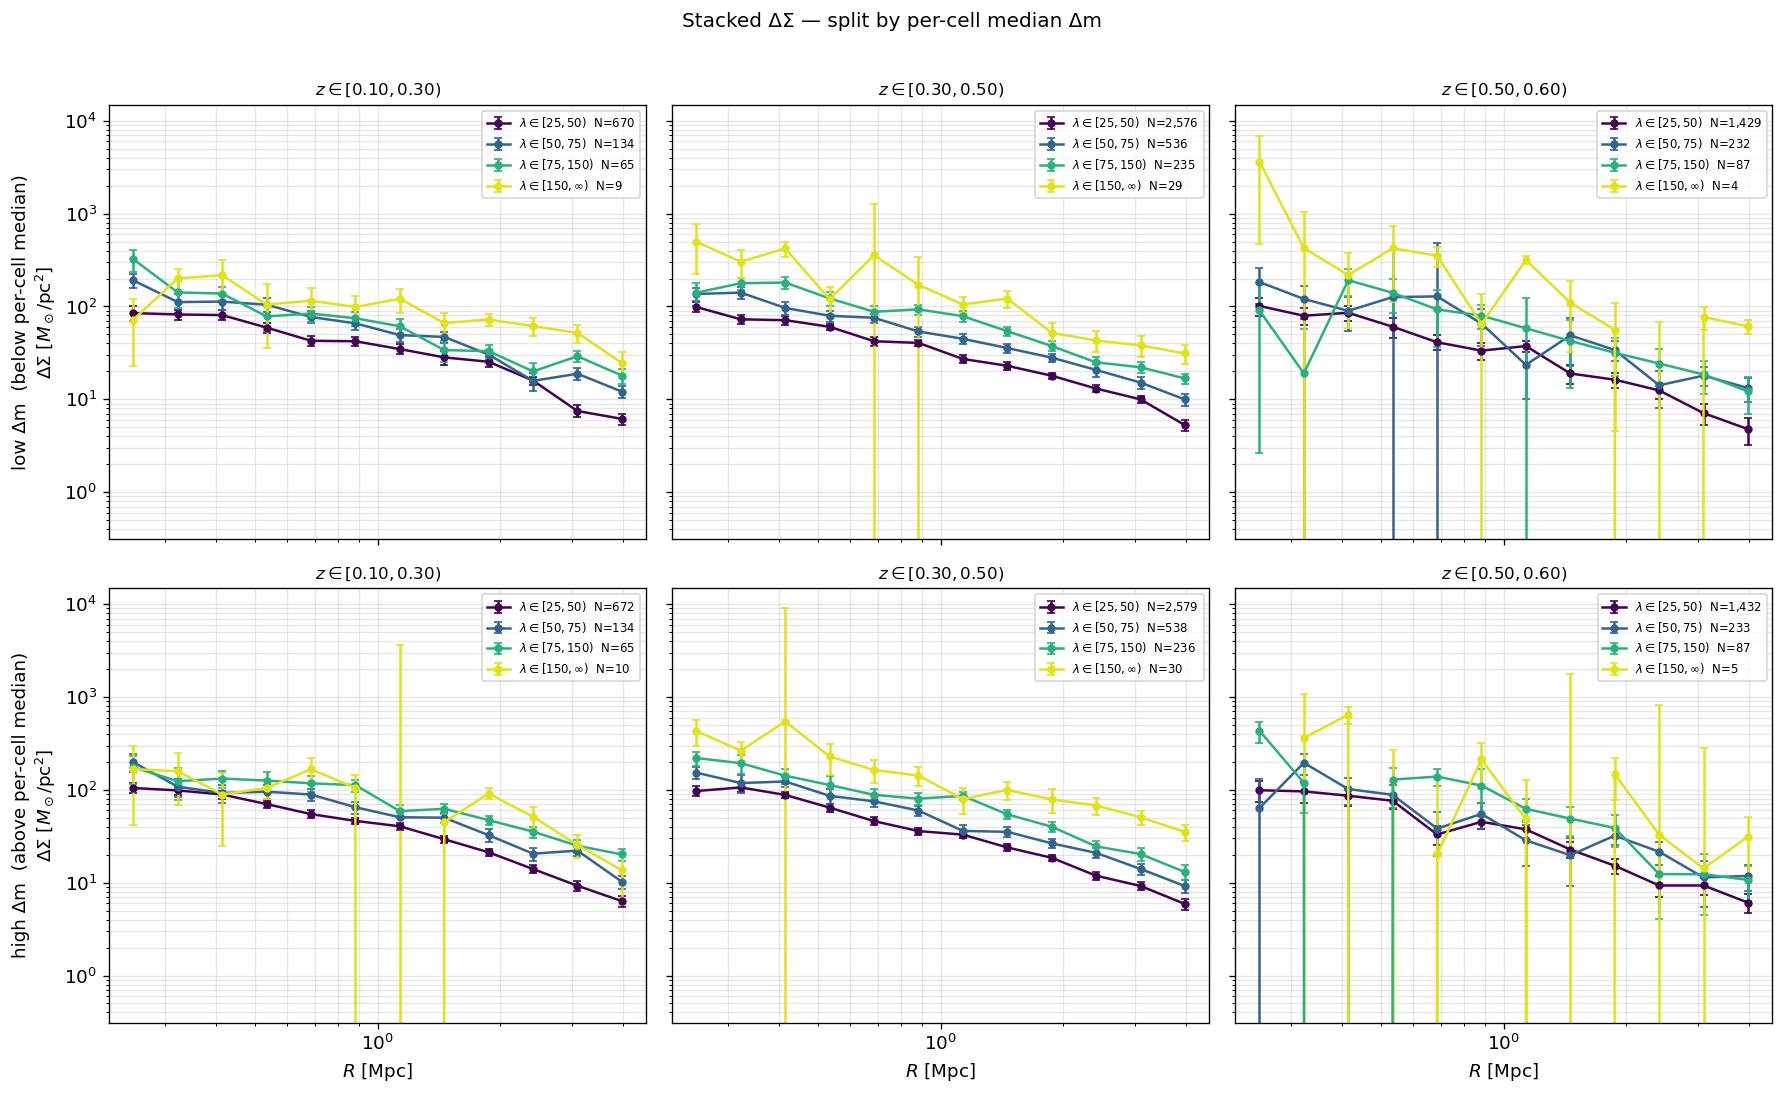

In [8]:
cmap = mpl.cm.viridis
ng_colors = [cmap(x) for x in np.linspace(0.0, 0.95, N_NG)]
dm_titles = {0: 'low Δm  (below per-cell median)',
             1: 'high Δm  (above per-cell median)'}
fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
for k in range(2):
    for i in range(3):
        ax = axes[k, i]
        for j in range(N_NG):
            name = f'z{i}_ng{j}_dm{k}'
            if name not in stacks: continue
            s   = stacks[name]
            err = np.sqrt(np.diag(s['sigmas_cov']))
            hi  = (f'{s["ng_hi"]:.0f}'
                   if np.isfinite(s["ng_hi"]) else r'\infty')
            ax.errorbar(radii, s['sigmas'], yerr=err,
                        fmt='o-', ms=4, capsize=2.5, color=ng_colors[j],
                        label=(rf'$\lambda\in[{s["ng_lo"]:.0f},{hi})$  '
                               f'N={s["n_stacked"]:,}'))
        ax.set_xscale('log')
        ax.set_yscale('log')
        if k == 1:
            ax.set_xlabel(r'$R$ [Mpc]')
        if i == 0:
            ax.set_ylabel(rf'{dm_titles[k]}'+'\n'+r'$\Delta\Sigma$ [$M_\odot/\mathrm{pc}^2$]')
        ax.set_title(rf'$z\in[{z_edges[i]:.2f},{z_edges[i+1]:.2f})$', fontsize=10)
        ax.grid(alpha=0.3, which='both')
        ax.legend(fontsize=7, loc='upper right')
plt.suptitle('Stacked ΔΣ — split by per-cell median Δm', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

## 6 — NFW + miscentering fits  (c fixed by colossus)

Free parameters per stack (3):

- `log10(M200c)` ∈ [13, 16]
- `FMISS` ∈ [0, 1]
- `SIGMA_OFF` ∈ [0.01, 1.0]  Mpc

Concentration is **not** free — each likelihood call evaluates
`c200c = colossus.halo.concentration.concentration(M*h, mdef='200c', z, model=CMR_MODEL)`
at the current $M$ (converted to $M_\odot/h$ for colossus) and the stack's mean redshift.
`BCG_B_MASS` is fixed at 0.

Parallelised across stacks with `multiprocess.Pool`, each nautilus run single-process. Robust to the bound-splitter "Number of points must be larger than number dimensions" error: retry once at higher `n_live`/`n_points_min`, then mark as failed.

In [9]:
PARAM_ORDER = ['log_M', 'FMISS', 'SIGMA_OFF']


def c_of_M_z(M_msun, z):
    """colossus c200c at (M [Msun], z).  Converts to Msun/h for colossus."""
    return float(colossus_conc.concentration(
        M=M_msun * COLOSSUS_H, mdef=CMR_MDEF, z=z, model=CMR_MODEL,
    ))


def _make_prior():
    p = Prior()
    p.add_parameter('log_M',     dist=(13.0, 16.0))
    p.add_parameter('FMISS',     dist=(0.0,  1.0))
    p.add_parameter('SIGMA_OFF', dist=(0.01, 1.0))
    return p


def _run_sampler(loglike, n_live, n_points_min=None, split_threshold=100):
    kwargs = dict(n_live=n_live, pool=None,
                  split_threshold=split_threshold)
    if n_points_min is not None:
        kwargs['n_points_min'] = n_points_min
    samp = Sampler(_make_prior(), loglike, **kwargs)
    samp.run(verbose=False)
    return samp


def fit_one(item):
    """
    Try nautilus at the default NLIVE.  If the bound splitter chokes
    ("Number of points must be larger than number dimensions"), retry with
    more live points, a larger minimum per-bound size, and a higher split
    threshold.  On a second failure, return a marker dict.
    """
    name, s = item
    cov_reg = s['sigmas_cov'] + 1e-6 * np.eye(len(s['sigmas'])) * np.mean(
        np.diag(s['sigmas_cov']))
    cov_inv = np.linalg.inv(cov_reg)
    data    = s['sigmas']
    z_eff   = s['z_mean']

    def loglike(p):
        try:
            M = 10.0 ** p['log_M']               # Msun
            C = c_of_M_z(M, z_eff)               # c200c from colossus
            if not np.isfinite(C) or C <= 0:
                return -np.inf
            out = xlensing.model.NFW_Delta_Sigma(
                M200m=np.array([M]),
                C200m=np.array([C]),
                Z=np.array([z_eff]),
                FMISS=np.array([p['FMISS']]),
                SIGMA_OFF=np.array([p['SIGMA_OFF']]),
                BCG_B_MASS=np.array([0.0]),
                radii=radii,
            )
            res = data - out['Signal'][0]
            return -0.5 * res @ cov_inv @ res
        except Exception:
            return -np.inf

    common = {
        'z_mean':      s['z_mean'],
        'lambda_mean': s['lambda_mean'],
        'dm_mean':     s['dm_mean'],
        'dm_bin':      s['dm_bin'],
        'n_stacked':   s['n_stacked'],
        'cmr_model':   CMR_MODEL,
        'cmr_mdef':    CMR_MDEF,
    }

    try:
        samp = _run_sampler(loglike, n_live=NLIVE)
    except ValueError:
        try:
            samp = _run_sampler(loglike,
                                n_live=max(NLIVE * 4, 2000),
                                n_points_min=50,
                                split_threshold=400)
        except Exception as exc2:
            return name, {'failed': True, 'error': repr(exc2), **common}
    except Exception as exc:
        return name, {'failed': True, 'error': repr(exc), **common}

    pts, lw, _ = samp.posterior()
    w = np.exp(lw - lw.max()); w = w / w.sum()

    def wq(x, q):
        srt = np.argsort(x); cum = np.cumsum(w[srt])
        return float(np.interp(q, cum, x[srt]))

    mean = {p: float(np.average(pts[:, i], weights=w))
            for i, p in enumerate(PARAM_ORDER)}
    qq   = {p: (wq(pts[:, i], 0.16), wq(pts[:, i], 0.84))
            for i, p in enumerate(PARAM_ORDER)}
    c_at_M_post = c_of_M_z(10.0 ** mean['log_M'], z_eff)

    return name, {
        'failed':      False,
        'mean':        mean,
        'quantiles':   qq,
        'samples':     pts.astype('float32'),
        'log_weights': lw.astype('float32'),
        'c_at_M_post': c_at_M_post,
        **common,
    }

In [10]:
# Incremental fit run: load cached fits, fit only the missing stacks, and
# persist after every completed fit so a crash never costs more than one
# stack of progress.
fits_out = {}
if os.path.exists(FITS_PKL) and USE_CACHE:
    with open(FITS_PKL, 'rb') as fh:
        fits_out = pickle.load(fh)
    print(f'Resumed {len(fits_out)} cached fits from {FITS_PKL}')
elif os.path.exists(FITS_PKL):
    print(f'USE_CACHE = False, ignoring existing {FITS_PKL} and refitting all stacks')

items_todo = [(n, s) for n, s in stacks.items() if n not in fits_out]
print(f'Fitting {len(items_todo)} stacks (out of {len(stacks)} total)')

if items_todo:
    n_par_workers = min(NWORKERS, len(items_todo))
    t0 = time.time()
    with Pool(n_par_workers) as pool:
        for k, (name, out) in enumerate(pool.imap_unordered(
                fit_one, items_todo)):
            fits_out[name] = out
            with open(FITS_PKL, 'wb') as fh:
                pickle.dump(fits_out, fh)
            dt  = time.time() - t0
            eta = dt * (len(items_todo) - k - 1) / (k + 1)
            n_clust = out.get('n_stacked', 0)
            if out.get('failed'):
                print(f'[{k+1:>2}/{len(items_todo)}] {name}  N={n_clust:>5,}: '
                      f"FAILED  {out['error'][:80]}  "
                      f'elapsed {dt/60:5.1f}m  eta {eta/60:5.1f}m', flush=True)
            else:
                m = out['mean']
                print(f'[{k+1:>2}/{len(items_todo)}] {name}  N={n_clust:>5,}: '
                      f"logM={m['log_M']:.3f}  c_CMR={out['c_at_M_post']:.2f}  "
                      f"fmiss={m['FMISS']:.2f}  σ_off={m['SIGMA_OFF']:.3f}  "
                      f'elapsed {dt/60:5.1f}m  eta {eta/60:5.1f}m', flush=True)

n_ok   = sum(1 for f in fits_out.values() if not f.get('failed'))
n_fail = sum(1 for f in fits_out.values() if     f.get('failed'))
print(f'\nTotal: {len(fits_out)} fits  ({n_ok} ok, {n_fail} failed) -> {FITS_PKL}')

USE_CACHE = False, ignoring existing data/wazp_mr_dm_colossus_fits.pkl and refitting all stacks
Fitting 24 stacks (out of 24 total)
[ 1/24] z0_ng3_dm1  N=   10: logM=15.182  c_CMR=3.83  fmiss=0.48  σ_off=0.905  elapsed   0.7m  eta  15.8m
[ 2/24] z0_ng2_dm0  N=   65: logM=14.649  c_CMR=3.81  fmiss=0.21  σ_off=0.390  elapsed   0.8m  eta   8.5m
[ 3/24] z0_ng3_dm0  N=    9: logM=15.174  c_CMR=3.82  fmiss=0.61  σ_off=0.057  elapsed   0.8m  eta   5.5m
[ 4/24] z1_ng2_dm1  N=  236: logM=14.733  c_CMR=3.75  fmiss=0.22  σ_off=0.246  elapsed   0.8m  eta   4.0m
[ 5/24] z0_ng1_dm1  N=  134: logM=14.554  c_CMR=3.86  fmiss=0.22  σ_off=0.261  elapsed   0.8m  eta   3.0m
[ 6/24] z1_ng3_dm0  N=   29: logM=14.913  c_CMR=3.77  fmiss=0.24  σ_off=0.354  elapsed   0.8m  eta   2.5m
[ 7/24] z1_ng2_dm0  N=  235: logM=14.764  c_CMR=3.75  fmiss=0.22  σ_off=0.228  elapsed   0.8m  eta   2.0m
[ 8/24] z0_ng2_dm1  N=   65: logM=14.883  c_CMR=3.76  fmiss=0.25  σ_off=0.247  elapsed   0.8m  eta   1.7m
[ 9/24] z1_ng0_dm0  

## 7 — M–λ power-law fits per Δm group

For each group (`dm=0` low / `dm=1` high) we run a weighted linear regression on

$$\log_{10} M_{200c} = \log_{10} M_0 + \alpha\,\log_{10}(\lambda/\lambda_{\rm piv}) + \beta\,\log_{10}((1+z)/(1+z_{\rm piv}))$$

with weights $1/\sigma_{\log M}^2$ (16/84 posterior half-width per stack). The analytic Gaussian posterior on $(\log M_0, \alpha, \beta)$ feeds the contour plot.

In [11]:
LAM_PIV, Z_PIV = 40.0, 0.35
MIN_N_FOR_FIT  = 10    # stacks with fewer clusters are excluded from M-λ fits

def gather(fits, dm_bin, min_n=MIN_N_FOR_FIT):
    rows = [(name, f) for name, f in fits.items()
            if f.get('dm_bin') == dm_bin
            and not f.get('failed', False)
            and f.get('n_stacked', 0) >= min_n]
    z    = np.array([r[1]['z_mean']      for r in rows])
    lam  = np.array([r[1]['lambda_mean'] for r in rows])
    logM = np.array([r[1]['mean']['log_M'] for r in rows])
    sig  = np.array([0.5 * (r[1]['quantiles']['log_M'][1]
                          - r[1]['quantiles']['log_M'][0]) for r in rows])
    names_kept = [r[0] for r in rows]
    return z, lam, logM, sig, names_kept

def joint_powerlaw(z, lam, logM, sig):
    X = np.column_stack([
        np.log10(lam / LAM_PIV),                # alpha
        np.log10((1.0 + z) / (1.0 + Z_PIV)),    # beta
        np.ones_like(lam),                      # logM0
    ])
    W   = np.diag(1.0 / sig**2)
    A   = X.T @ W @ X
    rhs = X.T @ W @ logM
    par = np.linalg.solve(A, rhs)
    cov = np.linalg.inv(A)
    return par, cov   # par = (alpha, beta, logM0)

# Report what was dropped before fitting
all_fits      = list(fits_out.items())
n_failed_all  = sum(1 for _, f in all_fits if f.get('failed'))
n_lowN_all    = sum(1 for _, f in all_fits
                    if not f.get('failed') and f.get('n_stacked', 0) < MIN_N_FOR_FIT)
print(f'Excluded from M–λ fits: {n_failed_all} failed + {n_lowN_all} with N<{MIN_N_FOR_FIT} clusters')
if n_lowN_all:
    for n, f in sorted(all_fits):
        if not f.get('failed') and f.get('n_stacked', 0) < MIN_N_FOR_FIT:
            print(f'   N<{MIN_N_FOR_FIT}: {n} (N={f.get("n_stacked", 0)})')

ml_fits = {}
for k in (0, 1):
    z, lam, logM, sig, names_kept = gather(fits_out, k)
    if len(z) < 4:
        print(f'dm={k}: only {len(z)} usable stacks (need ≥ 4), skipping')
        continue
    par, cov          = joint_powerlaw(z, lam, logM, sig)
    ml_fits[k] = {
        'mean':       {'alpha': par[0], 'beta': par[1], 'logM0': par[2]},
        'cov':        cov,
        'sigma':      np.sqrt(np.diag(cov)),
        'n_stacks':   len(z),
        'stacks_used':names_kept,
        'z':          z,  'lam': lam,  'logM': logM,  'sigM': sig,
    }
    s = ml_fits[k]['sigma']
    print(f'dm={k}  ({"low" if k==0 else "high"} Δm):  '
          f'log M0 = {par[2]:+.3f} ± {s[2]:.3f}   '
          f'α = {par[0]:+.3f} ± {s[0]:.3f}   '
          f'β = {par[1]:+.3f} ± {s[1]:.3f}   '
          f'(N={len(z)} stacks)')

with open(ML_PKL, 'wb') as fh:
    pickle.dump({'lam_piv': LAM_PIV, 'z_piv': Z_PIV,
                 'min_n_for_fit': MIN_N_FOR_FIT,
                 'ml_fits': ml_fits}, fh)

Excluded from M–λ fits: 1 failed + 2 with N<10 clusters
   N<10: z0_ng3_dm0 (N=9)
   N<10: z2_ng3_dm0 (N=4)
dm=0  (low Δm):  log M0 = +14.344 ± 0.014   α = +0.994 ± 0.055   β = -0.896 ± 0.429   (N=10 stacks)
dm=1  (high Δm):  log M0 = +14.380 ± 0.013   α = +1.143 ± 0.041   β = -2.227 ± 0.348   (N=11 stacks)


## 8 — Contour plot in $(\log M_0,\,\alpha,\,\beta)$

We draw 20 000 samples from each group's Gaussian posterior (mean + covariance from the weighted least squares) and overlay them in a corner-style figure to compare the two Δm samples.

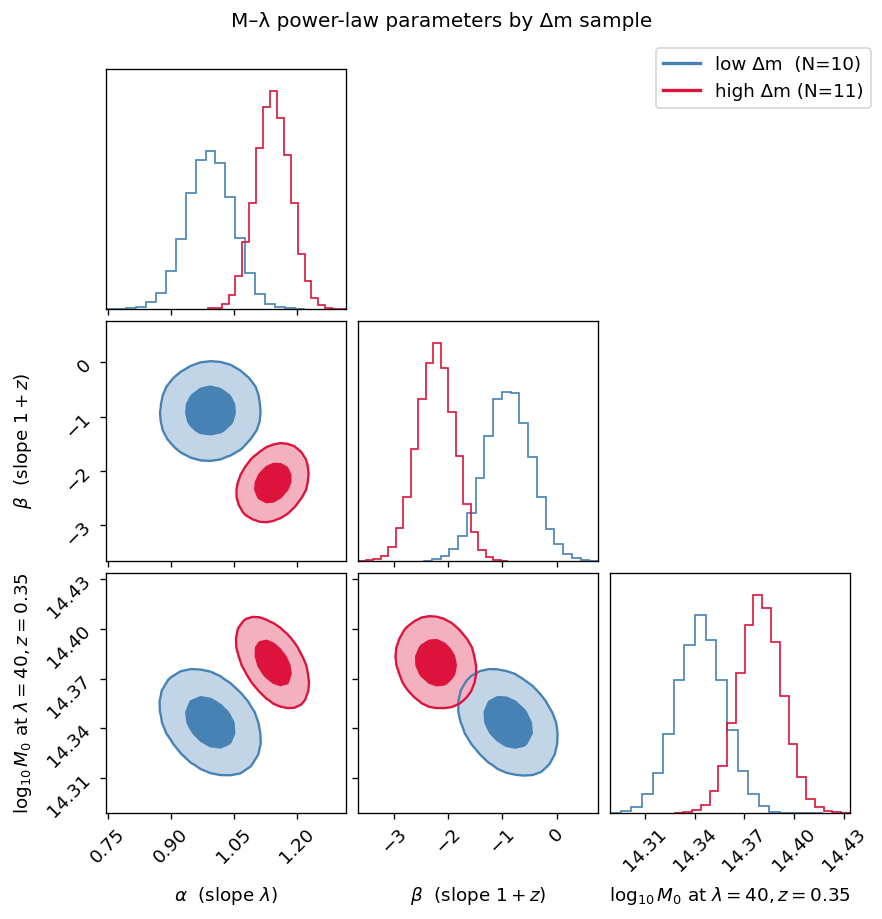


  Δ alpha (high − low) = +0.149 ± 0.069   (+2.16 σ)
  Δ  beta (high − low) = -1.332 ± 0.552   (-2.41 σ)
  Δ logM0 (high − low) = +0.036 ± 0.019   (+1.86 σ)


In [12]:
rng = np.random.default_rng(0)
NSMP = 20_000
param_names = ['alpha', 'beta', 'logM0']
labels = [r'$\alpha$  (slope $\lambda$)',
          r'$\beta$  (slope $1+z$)',
          rf'$\log_{{10}} M_0$ at $\lambda={LAM_PIV:.0f}, z={Z_PIV:.2f}$']

samples_low  = rng.multivariate_normal(
    [ml_fits[0]['mean'][p] for p in param_names],
    ml_fits[0]['cov'], size=NSMP)
samples_high = rng.multivariate_normal(
    [ml_fits[1]['mean'][p] for p in param_names],
    ml_fits[1]['cov'], size=NSMP)

fig = corner.corner(
    samples_low, labels=labels, color='steelblue',
    hist_kwargs={'density': True}, plot_datapoints=False,
    fill_contours=True, levels=(0.39, 0.86),  # 1σ / 2σ for 2D Gaussian
    smooth=1.0, contour_kwargs={'linewidths': 1.4},
)
corner.corner(
    samples_high, color='crimson',
    hist_kwargs={'density': True}, plot_datapoints=False,
    fill_contours=True, levels=(0.39, 0.86),
    smooth=1.0, contour_kwargs={'linewidths': 1.4},
    fig=fig,
)
from matplotlib.lines import Line2D
fig.legend(
    handles=[Line2D([0],[0], color='steelblue', lw=2,
                    label=f'low Δm  (N={ml_fits[0]["n_stacks"]})'),
             Line2D([0],[0], color='crimson',  lw=2,
                    label=f'high Δm (N={ml_fits[1]["n_stacks"]})')],
    loc='upper right', bbox_to_anchor=(0.98, 0.98), fontsize=11, frameon=True,
)
fig.suptitle('M–λ power-law parameters by Δm sample', fontsize=12, y=1.01)
plt.show()

# Difference between groups in each parameter (1-sample-difference Gaussian)
print()
for p in param_names:
    m0 = ml_fits[0]['mean'][p];  m1 = ml_fits[1]['mean'][p]
    s0 = ml_fits[0]['sigma'][param_names.index(p)]
    s1 = ml_fits[1]['sigma'][param_names.index(p)]
    diff = m1 - m0
    sigma_diff = np.sqrt(s0**2 + s1**2)
    print(f'  Δ{p:>6} (high − low) = {diff:+.3f} ± {sigma_diff:.3f}   '
          f'({diff/sigma_diff:+.2f} σ)')

## 9 — Mass–richness data + best-fit power laws

Per-stack $\log_{10}M$ vs $\lambda$ in three panels (one per z slice), with the two Δm groups overlaid in blue (low) and red (high). Filled circles are the stacks used in the fit; open `×` markers are stacks dropped by the $N \ge 10$ rule. The solid lines are the joint power law from §7 evaluated at each panel's mean $z$.

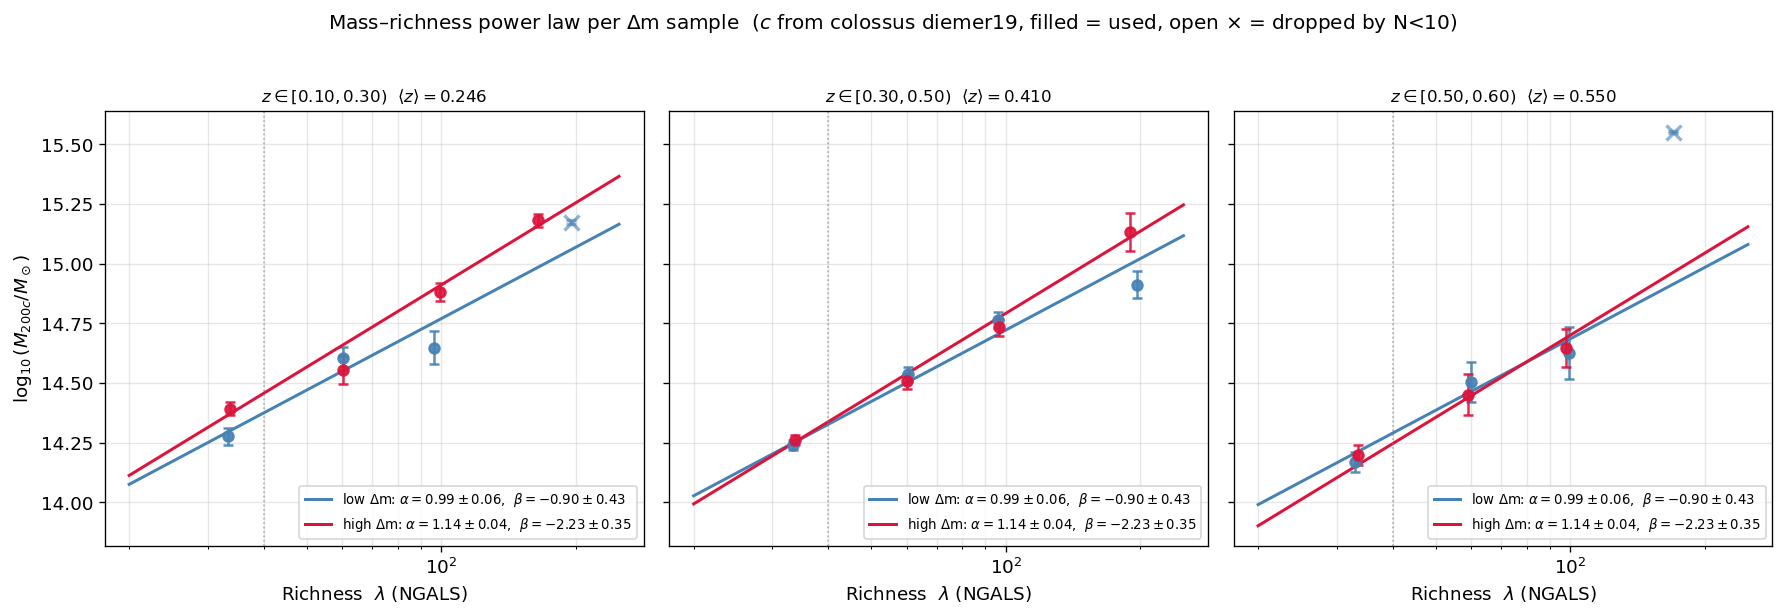

In [13]:
dm_colors = {0: 'steelblue', 1: 'crimson'}
dm_labels = {0: 'low Δm', 1: 'high Δm'}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
lam_smooth = np.geomspace(20, 250, 100)

for i in range(3):
    ax = axes[i]
    z_in_slice = [f['z_mean'] for n, f in fits_out.items()
                  if int(n.split('_')[0][1:]) == i and not f.get('failed')]
    z_slice_mean = float(np.mean(z_in_slice)) if z_in_slice else 0.5*(z_edges[i]+z_edges[i+1])

    for k in (0, 1):
        for name, f in fits_out.items():
            if int(name.split('_')[0][1:]) != i: continue
            if f.get('dm_bin') != k: continue
            if f.get('failed'): continue
            lam_pt  = f['lambda_mean']
            logM_pt = f['mean']['log_M']
            sig_pt  = 0.5 * (f['quantiles']['log_M'][1] - f['quantiles']['log_M'][0])
            n_clust = f['n_stacked']
            used    = n_clust >= MIN_N_FOR_FIT
            ax.errorbar(lam_pt, logM_pt, yerr=sig_pt,
                        fmt='o' if used else 'x',
                        ms=6 if used else 9,
                        mew=1.5 if used else 2,
                        color=dm_colors[k],
                        markerfacecolor=dm_colors[k] if used else 'none',
                        capsize=3, alpha=0.9 if used else 0.6)
        if k in ml_fits:
            m = ml_fits[k]['mean']
            logM_line = (m['logM0']
                         + m['alpha'] * np.log10(lam_smooth / LAM_PIV)
                         + m['beta']  * np.log10((1.0 + z_slice_mean) / (1.0 + Z_PIV)))
            s = ml_fits[k]['sigma']
            ax.plot(lam_smooth, logM_line, '-', color=dm_colors[k], lw=1.8,
                    label=(rf'{dm_labels[k]}: $\alpha={m["alpha"]:.2f}\pm{s[0]:.2f}$,  '
                           rf'$\beta={m["beta"]:.2f}\pm{s[1]:.2f}$'))
    ax.axvline(LAM_PIV, color='grey', ls=':', lw=1.0, alpha=0.6)
    ax.set_xscale('log')
    ax.set_xlabel(r'Richness  $\lambda$ (NGALS)')
    if i == 0:
        ax.set_ylabel(r'$\log_{10}(M_{200c}/M_\odot)$')
    ax.set_title(rf'$z\in[{z_edges[i]:.2f},{z_edges[i+1]:.2f})$  '
                 rf'$\langle z\rangle={z_slice_mean:.3f}$', fontsize=10)
    ax.grid(alpha=0.3, which='both')
    ax.legend(fontsize=8, loc='lower right')

plt.suptitle(rf'Mass–richness power law per Δm sample  '
             rf'($c$ from colossus {CMR_MODEL}, filled = used, '
             rf'open × = dropped by N<{MIN_N_FOR_FIT})',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.show()